# Análise Comparativa da Grade de Cenários de Veículos Elétricos (0% a 50%)
## Estudo de Caso: Alimentador Real ESB01S4 (Co-simulação Mosaik / OpenDSS / Caldera ICM)
### **Visualizações Gráficas, Conformidade Regulatória (PRODIST Módulo 8) e Degradação Térmica de Transformadores (IEEE Std C57.91)**

Este notebook constitui o ambiente analítico e de geração de figuras do TCC. Ele permite:
1. Carregar instantaneamente os resultados pré-computados das 66 simulações da grade de cenários (Caso Base + 10 patamares de penetração $\times$ 6 sementes de Monte Carlo);
2. Renderizar, customizar e exportar interativamente as **14 figuras acadêmicas** em altíssima resolução (600 DPI e PDF vetorial);
3. Avaliar indicadores regulatórios da ANEEL (PRODIST Módulo 8), o Índice de Desvio de Tensão (VDI - Nwobu et al., 2026), e o envelhecimento térmico dos transformadores de distribuição (IEEE Std C57.91).

**Autoria:** Paulo Victor Pereira Lima  
*Grupo de Redes Elétricas Inteligentes (GREI) / Departamento de Engenharia Elétrica / Universidade Federal do Ceará (UFC)*

In [1]:
import os
import sys
import json
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Localização robusta da raiz do projeto
curr = Path.cwd().resolve()
while curr.parent != curr:
    if (curr / "pyproject.toml").exists():
        PROJECT_ROOT = curr
        break
    curr = curr.parent
else:
    PROJECT_ROOT = Path("..").resolve()

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

OUTPUT_DIR = PROJECT_ROOT / "output"
CENARIOS_DIR = OUTPUT_DIR / "cenarios"
TABELAS_DIR = OUTPUT_DIR / "tabelas"
RELATORIOS_DIR = OUTPUT_DIR / "relatorios"
TOPOLOGIA_DIR = OUTPUT_DIR / "topologia"
FIGURAS_BASE_DIR = OUTPUT_DIR / "figuras"
FIGURAS_DIR = FIGURAS_BASE_DIR / "figuras_comparativas"
FIGURAS_DIR.mkdir(parents=True, exist_ok=True)

# Estilo visual acadêmico para o TCC (ABNT / IEEE)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9.5,
    "figure.titlesize": 14,
})

def salvar_figura(fig, nome_arquivo, dpi=600):
    caminho_png = FIGURAS_DIR / f"{nome_arquivo}.png"
    caminho_pdf = FIGURAS_DIR / f"{nome_arquivo}.pdf"
    fig.savefig(caminho_png, dpi=dpi, bbox_inches="tight")
    fig.savefig(caminho_pdf, bbox_inches="tight")
    print(f"Salvo: {caminho_png.name} e {caminho_pdf.name} ({dpi} DPI)")

print("Ambiente configurado com sucesso!")
print(f"Raiz do Projeto      : {PROJECT_ROOT}")
print(f"Figuras Comparativas : {FIGURAS_DIR}")

Ambiente configurado com sucesso!
Raiz do Projeto : /mnt/c/Users/pvict/OneDrive/TCC/ev-analysis-2026
Pasta de Saída  : /mnt/c/Users/pvict/OneDrive/TCC/ev-analysis-2026/output/figuras_comparativas


## Módulo 1: Carregamento dos Dados Consolidados
Carrega as tabelas pré-computadas contendo as médias e desvios-padrão de Monte Carlo (6 sementes) para toda a rede e para os 40 transformadores MT/BT.

In [2]:
# 1. Tabela comparativa do alimentador e rede BT
df_agregado = pd.read_csv(TABELAS_DIR / "tabela_comparativa_multissemente_resumo.csv")

# 2. Resumo dos 40 transformadores MT/BT
df_resumo_trafos = pd.read_csv(TABELAS_DIR / "tabela_carregamento_transformadores_resumo.csv")

# 3. Ranking de transformadores críticos
df_ranking_trafos = pd.read_csv(TABELAS_DIR / "tabela_transformadores_ranking_criticos.csv")

# 4. Dados detalhados de todos os 40 trafos por semente e penetração
df_detalhado = pd.read_csv(TABELAS_DIR / "tabela_carregamento_transformadores_detalhado.csv")

def carregar_ou_extrair_perfis(output_dir=OUTPUT_DIR, cenarios_dir=CENARIOS_DIR, tabelas_dir=TABELAS_DIR):
    csv_perf = tabelas_dir / "perfil_temporal_pior_barra_todos_cenarios.csv"
    if csv_perf.exists():
        return pd.read_csv(csv_perf)
    print("Arquivo consolidado de perfis não encontrado. Extraindo diretamente dos resultados dos cenários...")
    col_pior = "DSS-0.Bus-3864601538458035-V2_pu"
    df_p = pd.DataFrame({"hora": np.arange(1008) * (10.0 / 60.0)})
    # Caso Base (0% VEs)
    c_base = output_dir / "cenarios" / "caso_base" / "result_TCC_baseline.csv"
    if not c_base.exists():
        c_base = output_dir / "cenarios" / "result_TCC_baseline.csv"
    if c_base.exists():
        df_p["v_pu_p0"] = pd.read_csv(c_base, usecols=[col_pior])[col_pior].values
    # Cenários 5% a 50% VEs
    for p in range(5, 55, 5):
        candidatos = [
            output_dir / "cenarios" / "seed_42" / f"result_TCC_ev_p{p}_residencial_bt_seed42.csv",
            output_dir / "cenarios" / f"seed_42" / f"result_TCC_ev_p{p}_residencial_bt.csv",
            output_dir / "cenarios" / f"result_TCC_ev_p{p}_residencial_bt_seed42.csv",
        ]
        arq = next((c for c in candidatos if c.exists()), None)
        if arq is not None:
            df_p[f"v_pu_p{p}"] = pd.read_csv(arq, usecols=[col_pior])[col_pior].values
    tabelas_dir.mkdir(parents=True, exist_ok=True)
    df_p.to_csv(csv_perf, index=False)
    print(f"Perfis temporais extraídos e salvos com sucesso em: {csv_perf.name}")
    return df_p

# 5. Perfis temporais da pior barra em todos os cenários
df_perfis = carregar_ou_extrair_perfis()

# 6. Informações da barra mais afetada
with open(TOPOLOGIA_DIR / "barra_bt_mais_afetada.json", "r", encoding="utf-8") as f:
    info_barra = json.load(f)

p_pct = df_agregado["penetracao_pct"].values
trafo_mais_critico = df_ranking_trafos.iloc[0]["trafo"]
s_nom_critico = float(df_ranking_trafos.iloc[0]["s_nom_kva"])

print(f"Dados consolidados carregados com sucesso:")
print(f"- Cenários de Penetração : {list(p_pct)}% VEs")
print(f"- Barra BT Mais Crítica  : {info_barra['bus']} ({info_barra['distancia_km']:.2f} km da SE)")
print(f"- Trafo Mais Crítico     : {trafo_mais_critico} ({s_nom_critico:.0f} kVA)")
df_agregado[["cenario", "penetracao_pct", "qtd_evs", "p_max_kw_media", "pct_delta_p_max_media", "v_min_pu_media", "delta_n_barras_drc_sub_media"]].head()

Arquivo consolidado de perfis não encontrado. Extraindo diretamente dos resultados dos cenários...
Perfis temporais extraídos e salvos com sucesso em: perfil_temporal_pior_barra_todos_cenarios.csv
Dados consolidados carregados com sucesso:
- Cenários de Penetração : [np.int64(0), np.int64(5), np.int64(10), np.int64(15), np.int64(20), np.int64(25), np.int64(30), np.int64(35), np.int64(40), np.int64(45), np.int64(50)]% VEs
- Barra BT Mais Crítica  : 3864601538458035 (7.33 km da SE)
- Trafo Mais Crítico     : TRF_29L2218A (75 kVA)


,cenario,penetracao_pct,qtd_evs,p_max_kw_media,pct_delta_p_max_media,v_min_pu_media,delta_n_barras_drc_sub_media
0,Caso Base,0,0,1705.901913,0.000000,0.894612,0.000000
1,5% VEs,5,47,1709.562607,0.214590,0.844796,25.166667
2,10% VEs,10,95,1714.773766,0.520068,0.823330,67.666667
3,15% VEs,15,142,1732.034581,1.531897,0.811661,103.333333
4,20% VEs,20,189,1747.588808,2.443686,0.797132,174.833333


## Módulo 2: Curvas de Impacto no Alimentador e Tensão na Baixa Tensão (Figuras 1 a 7)

Salvo: fig1_impacto_relativo_pico_energia.png e fig1_impacto_relativo_pico_energia.pdf (600 DPI)


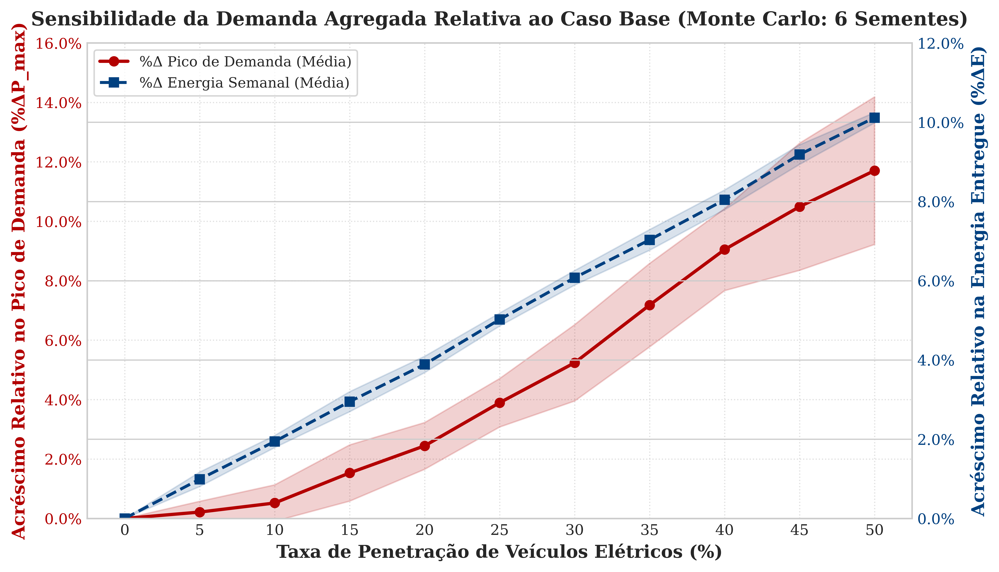

In [3]:
# FIGURA 1: Impacto Relativo no Pico de Demanda e na Energia Semanal
fig, ax1 = plt.subplots(figsize=(9.5, 5.5), dpi=600)
color1, color2 = "#b30000", "#004080"

ax1.set_xlabel("Taxa de Penetração de Veículos Elétricos (%)", fontweight="bold")
ax1.set_ylabel("Acréscimo Relativo no Pico de Demanda (%ΔP_max)", color=color1, fontweight="bold")
m_pmax = df_agregado["pct_delta_p_max_media"].values
s_pmax = df_agregado["pct_delta_p_max_std"].values

line1 = ax1.plot(p_pct, m_pmax, marker="o", color=color1, linewidth=2.2, markersize=6, label="%Δ Pico de Demanda (Média)")
ax1.fill_between(p_pct, m_pmax - s_pmax, m_pmax + s_pmax, color=color1, alpha=0.18, label="Dispersão Sementes (±1σ)")
ax1.tick_params(axis="y", labelcolor=color1)
ax1.yaxis.set_major_formatter(ticker.PercentFormatter(decimals=1))
ax1.set_ylim(0, 16)
ax1.yaxis.set_major_locator(ticker.MultipleLocator(2))

ax2 = ax1.twinx()
ax2.set_ylabel("Acréscimo Relativo na Energia Entregue (%ΔE)", color=color2, fontweight="bold")
m_ene = df_agregado["pct_delta_energia_media"].values
s_ene = df_agregado["pct_delta_energia_std"].values

line2 = ax2.plot(p_pct, m_ene, marker="s", color=color2, linewidth=2.0, linestyle="--", markersize=6, label="%Δ Energia Semanal (Média)")
ax2.fill_between(p_pct, m_ene - s_ene, m_ene + s_ene, color=color2, alpha=0.15)
ax2.tick_params(axis="y", labelcolor=color2)
ax2.yaxis.set_major_formatter(ticker.PercentFormatter(decimals=1))
ax2.set_ylim(0, 12)
ax2.yaxis.set_major_locator(ticker.MultipleLocator(2))

ax1.set_xticks(p_pct)
ax1.grid(True, linestyle=":", alpha=0.6)
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left", frameon=True)
plt.title("Sensibilidade da Demanda Agregada Relativa ao Caso Base (Monte Carlo: 6 Sementes)", fontweight="bold", pad=12)
plt.tight_layout()
salvar_figura(fig, "fig1_impacto_relativo_pico_energia")
plt.show()

Salvo: fig2_hosting_capacity_novas_barras_prodist.png e fig2_hosting_capacity_novas_barras_prodist.pdf (600 DPI)


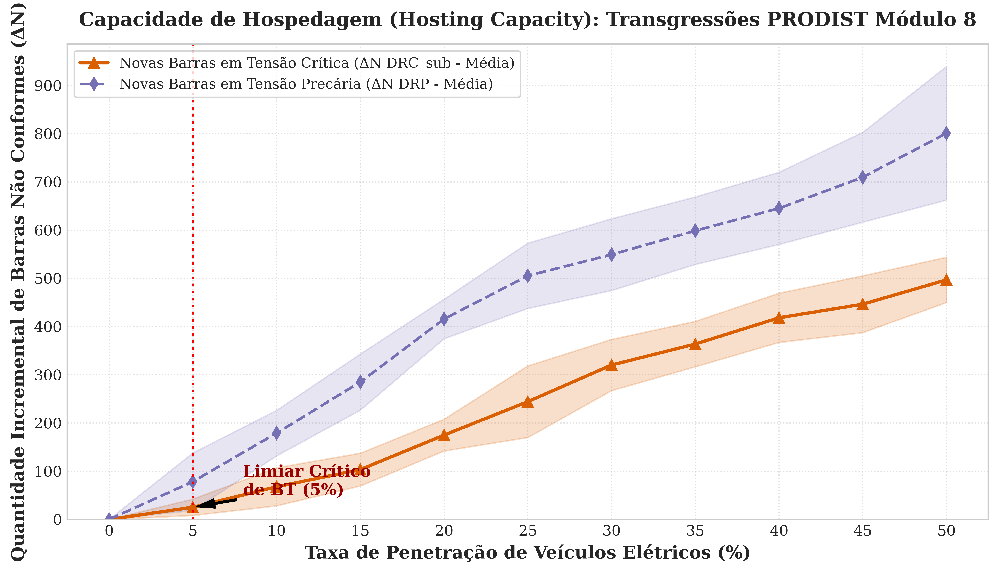

In [4]:
# FIGURA 2: Capacidade de Hospedagem (Hosting Capacity) e Novas Transgressões PRODIST
fig, ax = plt.subplots(figsize=(9.5, 5.5), dpi=600)
m_drc = df_agregado["delta_n_barras_drc_sub_media"].values
s_drc = df_agregado["delta_n_barras_drc_sub_std"].values
m_drp = df_agregado["delta_n_barras_drp_media"].values
s_drp = df_agregado["delta_n_barras_drp_std"].values

ax.plot(p_pct, m_drc, marker="^", color="#d95f02", linewidth=2.2, markersize=7, label="Novas Barras em Tensão Crítica (ΔN DRC_sub - Média)")
ax.fill_between(p_pct, np.maximum(0, m_drc - s_drc), m_drc + s_drc, color="#d95f02", alpha=0.2)
ax.plot(p_pct, m_drp, marker="d", color="#7570b3", linewidth=1.8, linestyle="--", markersize=6, label="Novas Barras em Tensão Precária (ΔN DRP - Média)")
ax.fill_between(p_pct, np.maximum(0, m_drp - s_drp), m_drp + s_drp, color="#7570b3", alpha=0.18)

ax.set_xlabel("Taxa de Penetração de Veículos Elétricos (%)", fontweight="bold")
ax.set_ylabel("Quantidade Incremental de Barras Não Conformes (ΔN)", fontweight="bold")
ax.set_xticks(p_pct)
ax.set_ylim(bottom=0)
ax.yaxis.set_major_locator(ticker.MultipleLocator(100))
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper left", frameon=True)

idx_hc = df_agregado[df_agregado["delta_n_barras_drc_sub_media"] > 0].index
if len(idx_hc) > 0:
    p_hc = df_agregado.loc[idx_hc[0], "penetracao_pct"]
    ax.axvline(p_hc, color="red", linestyle=":", linewidth=1.8, label=f"Limiar de Hosting Capacity ({p_hc}%)")
    ax.annotate(
        f"Limiar Crítico\nde BT ({p_hc}%)",
        xy=(p_hc, df_agregado.loc[idx_hc[0], "delta_n_barras_drc_sub_media"]),
        xytext=(p_hc + 3, df_agregado.loc[idx_hc[0], "delta_n_barras_drc_sub_media"] + 25),
        arrowprops=dict(facecolor="black", shrink=0.08, width=1, headwidth=6),
        fontweight="bold", color="#990000"
    )

plt.title("Capacidade de Hospedagem (Hosting Capacity): Transgressões PRODIST Módulo 8", fontweight="bold", pad=12)
plt.tight_layout()
salvar_figura(fig, "fig2_hosting_capacity_novas_barras_prodist")
plt.show()

Salvo: fig3_vdi_subtensao_relativo.png e fig3_vdi_subtensao_relativo.pdf (600 DPI)


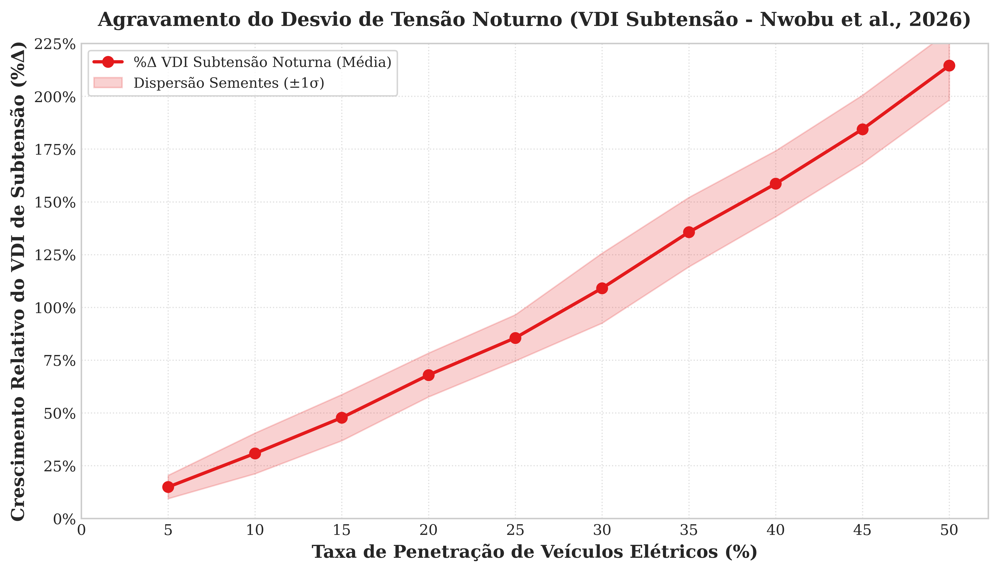

In [5]:
# FIGURA 3: Degradação Relativa do VDI de Subtensão vs. Sobretensão
fig, ax = plt.subplots(figsize=(9.5, 5.5), dpi=600)
m_vdi = df_agregado["pct_delta_vdi_sub_media"].values
s_vdi = df_agregado["pct_delta_vdi_sub_std"].values

ax.plot(p_pct[1:], m_vdi[1:], marker="o", color="#e41a1c", linewidth=2.2, markersize=7, label="%Δ VDI Subtensão Noturna (Média)")
ax.fill_between(p_pct[1:], np.maximum(0, m_vdi[1:] - s_vdi[1:]), m_vdi[1:] + s_vdi[1:], color="#e41a1c", alpha=0.2, label="Dispersão Sementes (±1σ)")
ax.set_xlabel("Taxa de Penetração de Veículos Elétricos (%)", fontweight="bold")
ax.set_ylabel("Crescimento Relativo do VDI de Subtensão (%Δ)", fontweight="bold")
ax.set_xticks(p_pct)
ax.set_ylim(0, 225)
ax.yaxis.set_major_locator(ticker.MultipleLocator(25))
ax.yaxis.set_major_formatter(ticker.PercentFormatter(decimals=0))
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper left", frameon=True)
plt.title("Agravamento do Desvio de Tensão Noturno (VDI Subtensão - Nwobu et al., 2026)", fontweight="bold", pad=12)
plt.tight_layout()
salvar_figura(fig, "fig3_vdi_subtensao_relativo")
plt.show()

Salvo: fig4_tensao_minima_global_prodist.png e fig4_tensao_minima_global_prodist.pdf (600 DPI)


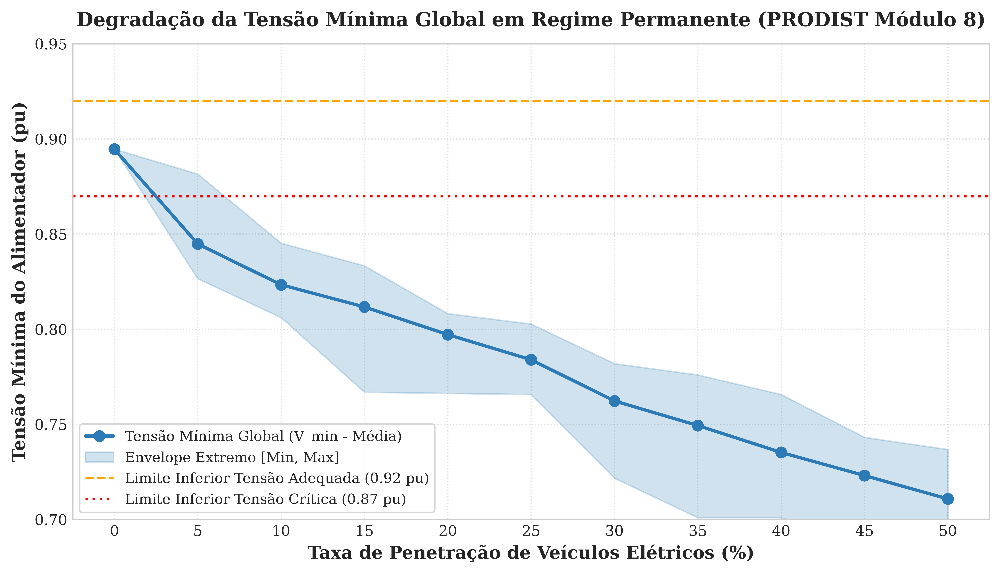

In [6]:
# FIGURA 4: Afundamento da Tensão Mínima Global (ΔV_min)
fig, ax = plt.subplots(figsize=(9.5, 5.5), dpi=600)
m_vmin = df_agregado["v_min_pu_media"].values
s_vmin = df_agregado["v_min_pu_std"].values
min_vmin = df_agregado["v_min_pu_min"].values
max_vmin = df_agregado["v_min_pu_max"].values

ax.plot(p_pct, m_vmin, marker="o", color="#2c7bb6", linewidth=2.2, markersize=7, label="Tensão Mínima Global (V_min - Média)")
ax.fill_between(p_pct, min_vmin, max_vmin, color="#2c7bb6", alpha=0.22, label="Envelope Extremo [Min, Max]")
ax.axhline(0.92, color="orange", linestyle="--", linewidth=1.5, label="Limite Inferior Tensão Adequada (0.92 pu)")
ax.axhline(0.87, color="red", linestyle=":", linewidth=1.8, label="Limite Inferior Tensão Crítica (0.87 pu)")

ax.set_xlabel("Taxa de Penetração de Veículos Elétricos (%)", fontweight="bold")
ax.set_ylabel("Tensão Mínima do Alimentador (pu)", fontweight="bold")
ax.set_xticks(p_pct)
ax.set_ylim(0.70, 0.95)
ax.set_yticks(np.arange(0.70, 0.96, 0.05))
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower left", frameon=True)
plt.title("Degradação da Tensão Mínima Global em Regime Permanente (PRODIST Módulo 8)", fontweight="bold", pad=12)
plt.tight_layout()
salvar_figura(fig, "fig4_tensao_minima_global_prodist")
plt.show()

Salvo: fig5_tensao_media_global_todas_barras.png e fig5_tensao_media_global_todas_barras.pdf (600 DPI)


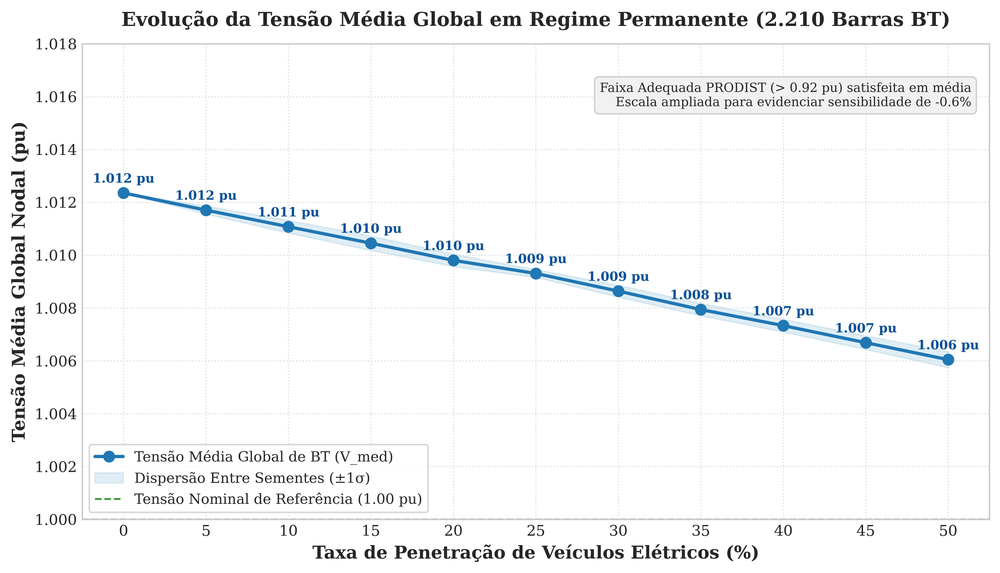

In [7]:
# FIGURA 5: Evolução da Tensão Média Global de Todas as Barras de BT
fig, ax = plt.subplots(figsize=(9.5, 5.5), dpi=600)
m_vmed = df_agregado["v_med_pu_media"].values
s_vmed = df_agregado["v_med_pu_std"].values

ax.plot(p_pct, m_vmed, marker="o", color="#1f78b4", linewidth=2.2, markersize=7, label="Tensão Média Global de BT (V_med)")
ax.fill_between(p_pct, m_vmed - s_vmed, m_vmed + s_vmed, color="#a6cee3", alpha=0.35, label="Dispersão Entre Sementes (±1σ)")
ax.axhline(1.00, color="green", linestyle="--", linewidth=1.2, alpha=0.8, label="Tensão Nominal de Referência (1.00 pu)")

for x_i, y_i in zip(p_pct, m_vmed):
    ax.annotate(
        f"{y_i:.3f} pu", xy=(x_i, y_i), xytext=(0, 7),
        textcoords="offset points", ha="center", fontsize=8.5, fontweight="bold", color="#08519c"
    )

ax.set_xlabel("Taxa de Penetração de Veículos Elétricos (%)", fontweight="bold")
ax.set_ylabel("Tensão Média Global Nodal (pu)", fontweight="bold")
ax.set_xticks(p_pct)
ax.set_ylim(1.000, 1.018)
ax.set_yticks(np.arange(1.000, 1.019, 0.002))
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower left", frameon=True)

ax.text(
    0.98, 0.92,
    "Faixa Adequada PRODIST (> 0.92 pu) satisfeita em média\nEscala ampliada para evidenciar sensibilidade de -0.6%",
    transform=ax.transAxes, fontsize=8.5, ha="right", va="top",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#f0f0f0", edgecolor="#cccccc", alpha=0.9)
)

plt.title("Evolução da Tensão Média Global em Regime Permanente (2.210 Barras BT)", fontweight="bold", pad=12)
plt.tight_layout()
salvar_figura(fig, "fig5_tensao_media_global_todas_barras")
plt.show()

Salvo: fig6_perfil_semanal_barra_mais_afetada.png e fig6_perfil_semanal_barra_mais_afetada.pdf (600 DPI)


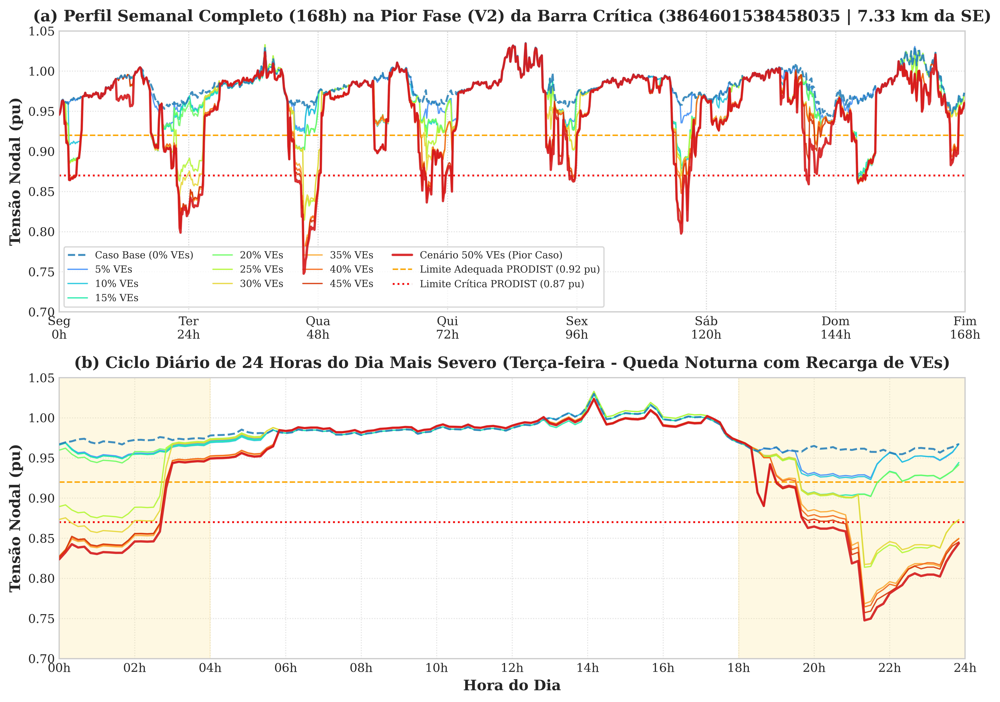

In [8]:
# FIGURA 6: Perfil Temporal Semanal (168h) e Ciclo Diário 24h na Pior Barra em Todos os Cenários
if 'df_perfis' not in globals() or df_perfis is None:
    df_perfis = carregar_ou_extrair_perfis()

fig, (ax_sem, ax_dia) = plt.subplots(2, 1, figsize=(11.5, 8.2), dpi=600)
t_horas = np.arange(1008) * (10.0 / 60.0)
nomes_dias = ["Segunda-feira", "Terça-feira", "Quarta-feira", "Quinta-feira", "Sexta-feira", "Sábado", "Domingo"]
dia_idx = 2

if df_perfis is not None and not df_perfis.empty:
    colunas_cenarios = [c for c in df_perfis.columns if c.startswith("v_pu_p")]
    cenarios_perf = sorted([int(c.replace("v_pu_p", "")) for c in colunas_cenarios])
    n_c = len(cenarios_perf)
    cores_lista = plt.cm.turbo(np.linspace(0.1, 0.95, n_c)) if "turbo" in plt.colormaps else plt.cm.jet(np.linspace(0.1, 0.9, n_c))
    
    s_50 = df_perfis["v_pu_p50"].values if "v_pu_p50" in df_perfis.columns else df_perfis[colunas_cenarios[-1]].values
    t_min_idx = int(np.argmin(s_50))
    dia_idx = min(6, t_min_idx // 144)
    dia_inicio, dia_fim = dia_idx * 144, (dia_idx + 1) * 144
    t_dia = np.arange(144) * (10.0 / 60.0)
    
    for idx, p in enumerate(cenarios_perf):
        serie = df_perfis[f"v_pu_p{p}"].values
        if p == 0:
            cor, lw, ls, lbl, z = "#2b83ba", 1.6, "--", "Caso Base (0% VEs)", 5
        elif p == 50:
            cor, lw, ls, lbl, z = "#d7191c", 1.9, "-", "Cenário 50% VEs (Pior Caso)", 6
        else:
            cor, lw, ls, lbl, z = cores_lista[idx], 1.05, "-", f"{p}% VEs", 3
            
        ax_sem.plot(t_horas, serie, color=cor, linewidth=lw, linestyle=ls, label=lbl, alpha=0.9, zorder=z)
        ax_dia.plot(t_dia, serie[dia_inicio:dia_fim], color=cor, linewidth=lw, linestyle=ls, label=lbl, alpha=0.9, zorder=z)

# Subplot 1 (Semanal 168h)
ax_sem.axhline(0.92, color="orange", linestyle="--", linewidth=1.2, label="Limite Adequada PRODIST (0.92 pu)")
ax_sem.axhline(0.87, color="red", linestyle=":", linewidth=1.5, label="Limite Crítica PRODIST (0.87 pu)")
ax_sem.set_ylabel("Tensão Nodal (pu)", fontweight="bold")
ax_sem.set_xlim(0, 168)
ax_sem.set_ylim(0.70, 1.05)
ax_sem.set_xticks(np.arange(0, 169, 24))
ax_sem.set_xticklabels(["Seg\n0h", "Ter\n24h", "Qua\n48h", "Qui\n72h", "Sex\n96h", "Sáb\n120h", "Dom\n144h", "Fim\n168h"])
for dh in range(24, 168, 24):
    ax_sem.axvline(dh, color="#cccccc", linestyle=":", linewidth=0.8, alpha=0.7)
ax_sem.grid(True, linestyle=":", alpha=0.6)
ax_sem.set_title(f"(a) Perfil Semanal Completo (168h) na Pior Fase (V2) da Barra Crítica ({info_barra['bus']} | {info_barra['distancia_km']:.2f} km da SE)", fontweight="bold", pad=8)

# Subplot 2 (Diário 24h)
ax_dia.axvspan(18.0, 24.0, color="#fee08b", alpha=0.25, label="Janela Noturna de Recarga (18h-04h)")
ax_dia.axvspan(0.0, 4.0, color="#fee08b", alpha=0.25)
ax_dia.axhline(0.92, color="orange", linestyle="--", linewidth=1.2)
ax_dia.axhline(0.87, color="red", linestyle=":", linewidth=1.5)
ax_dia.set_xlabel("Hora do Dia", fontweight="bold")
ax_dia.set_ylabel("Tensão Nodal (pu)", fontweight="bold")
ax_dia.set_xlim(0, 24)
ax_dia.set_ylim(0.70, 1.05)
ax_dia.set_xticks(np.arange(0, 25, 2))
ax_dia.set_xticklabels([f"{h:02d}h" for h in range(0, 25, 2)])
ax_dia.grid(True, linestyle=":", alpha=0.6)
ax_dia.set_title(f"(b) Ciclo Diário de 24 Horas do Dia Mais Severo ({nomes_dias[dia_idx]} - Queda Noturna com Recarga de VEs)", fontweight="bold", pad=8)

handles, labels = ax_sem.get_legend_handles_labels()
ax_sem.legend(handles, labels, loc="lower left", ncol=4, frameon=True, fontsize=8.0)
plt.tight_layout()
salvar_figura(fig, "fig6_perfil_semanal_barra_mais_afetada")
plt.show()

Salvo: fig7_sensibilidade_tensao_barra_mais_afetada.png e fig7_sensibilidade_tensao_barra_mais_afetada.pdf (600 DPI)


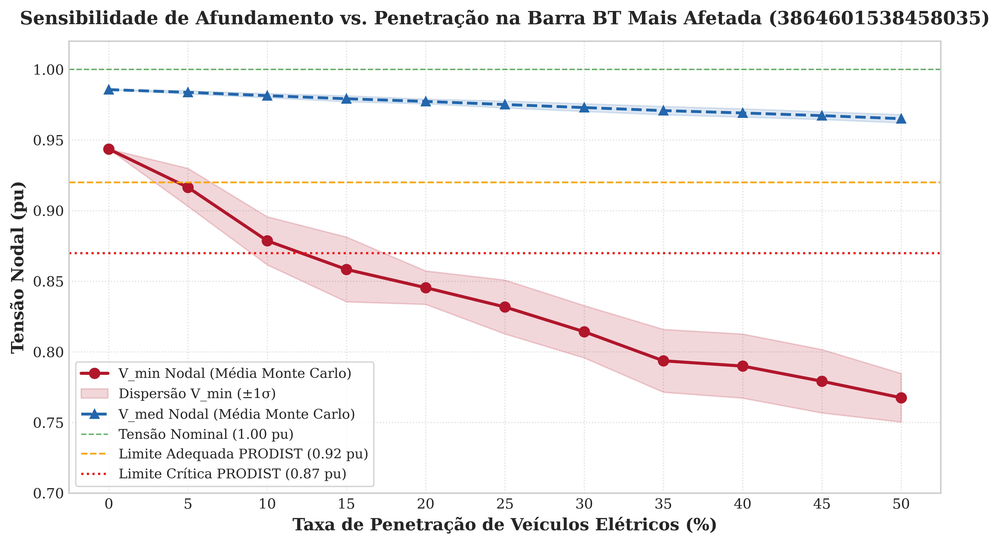

In [9]:
# FIGURA 7: Sensibilidade de Afundamento vs. Penetração na Barra BT Mais Afetada
fig, ax_sens = plt.subplots(figsize=(9.5, 5.5), dpi=600)
m_afetada_min = df_agregado["v_afetada_min_pu_media"].values
s_afetada_min = df_agregado["v_afetada_min_pu_std"].values
m_afetada_med = df_agregado["v_afetada_med_pu_media"].values
s_afetada_med = df_agregado["v_afetada_med_pu_std"].values

ax_sens.plot(p_pct, m_afetada_min, marker="o", color="#b2182b", linewidth=2.2, markersize=7, label="V_min Nodal (Média Monte Carlo)")
ax_sens.fill_between(p_pct, m_afetada_min - s_afetada_min, m_afetada_min + s_afetada_min, color="#b2182b", alpha=0.18, label="Dispersão V_min (±1σ)")

ax_sens.plot(p_pct, m_afetada_med, marker="^", color="#2166ac", linewidth=2.0, linestyle="--", markersize=6, label="V_med Nodal (Média Monte Carlo)")
ax_sens.fill_between(p_pct, m_afetada_med - s_afetada_med, m_afetada_med + s_afetada_med, color="#2166ac", alpha=0.15)

ax_sens.axhline(1.00, color="green", linestyle="--", linewidth=1.0, alpha=0.6, label="Tensão Nominal (1.00 pu)")
ax_sens.axhline(0.92, color="orange", linestyle="--", linewidth=1.2, label="Limite Adequada PRODIST (0.92 pu)")
ax_sens.axhline(0.87, color="red", linestyle=":", linewidth=1.5, label="Limite Crítica PRODIST (0.87 pu)")
ax_sens.set_xlabel("Taxa de Penetração de Veículos Elétricos (%)", fontweight="bold")
ax_sens.set_ylabel("Tensão Nodal (pu)", fontweight="bold")
ax_sens.set_xticks(p_pct)
ax_sens.set_ylim(0.70, 1.02)
ax_sens.set_yticks(np.arange(0.70, 1.03, 0.05))
ax_sens.grid(True, linestyle=":", alpha=0.6)
ax_sens.legend(loc="lower left", frameon=True, fontsize=9.5)
ax_sens.set_title(f"Sensibilidade de Afundamento vs. Penetração na Barra BT Mais Afetada ({info_barra['bus']})", fontweight="bold", pad=12)
plt.tight_layout()
salvar_figura(fig, "fig7_sensibilidade_tensao_barra_mais_afetada")
plt.show()

## Módulo 3: Curvas de Carregamento e Degradação Térmica dos Transformadores MT/BT (Figuras 8 a 14)

Salvo: fig8_trafo_curva_carga_24h_resfriamento_noturno.png e fig8_trafo_curva_carga_24h_resfriamento_noturno.pdf (600 DPI)


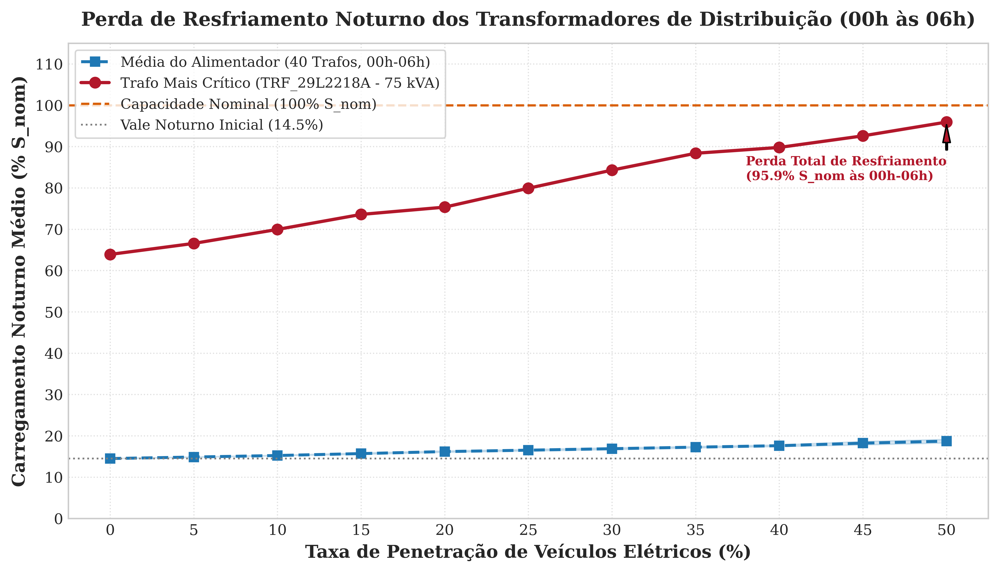

In [10]:
# FIGURA 8: Perda de Resfriamento Noturno dos Transformadores (00h às 06h)
fig, ax = plt.subplots(figsize=(9.5, 5.5), dpi=600)
m_noite = df_resumo_trafos["resfriamento_noturno_media"].values
s_noite = df_resumo_trafos["resfriamento_noturno_std"].values

ax.plot(p_pct, m_noite, marker="s", color="#1f78b4", linewidth=2.0, linestyle="--", markersize=6, label="Média do Alimentador (40 Trafos, 00h-06h)")
ax.fill_between(p_pct, m_noite - s_noite, m_noite + s_noite, color="#1f78b4", alpha=0.18)

sub_crit = df_detalhado[df_detalhado["trafo"] == trafo_mais_critico]
crit_noite = sub_crit.groupby("penetracao_pct")["fc_noite_med_pct"].mean()
crit_p = crit_noite.index.values
crit_vals = crit_noite.values
ax.plot(crit_p, crit_vals, marker="o", color="#b2182b", linewidth=2.2, markersize=7, label=f"Trafo Mais Crítico ({trafo_mais_critico} - {s_nom_critico:.0f} kVA)")
ax.annotate(
    f"Perda Total de Resfriamento\n({crit_vals[-1]:.1f}% S_nom às 00h-06h)",
    xy=(crit_p[-1], crit_vals[-1]),
    xytext=(crit_p[-1] - 12, crit_vals[-1] - 14),
    arrowprops=dict(facecolor="#b2182b", shrink=0.08, width=1, headwidth=5),
    fontsize=8.5, fontweight="bold", color="#b2182b"
)

ax.axhline(100.0, color="#d95f02", linestyle="--", linewidth=1.5, label="Capacidade Nominal (100% S_nom)")
val_base = m_noite[0]
ax.axhline(val_base, color="gray", linestyle=":", linewidth=1.2, label=f"Vale Noturno Inicial ({val_base:.1f}%)")

ax.set_xlabel("Taxa de Penetração de Veículos Elétricos (%)", fontweight="bold")
ax.set_ylabel("Carregamento Noturno Médio (% S_nom)", fontweight="bold")
ax.set_xticks(p_pct)
ax.set_ylim(0, 115)
ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper left", frameon=True)
plt.title("Perda de Resfriamento Noturno dos Transformadores de Distribuição (00h às 06h)", fontweight="bold", pad=12)
plt.tight_layout()
salvar_figura(fig, "fig8_trafo_curva_carga_24h_resfriamento_noturno")
plt.show()

Salvo: fig9_trafo_sobrecarga_vs_penetracao.png e fig9_trafo_sobrecarga_vs_penetracao.pdf (600 DPI)


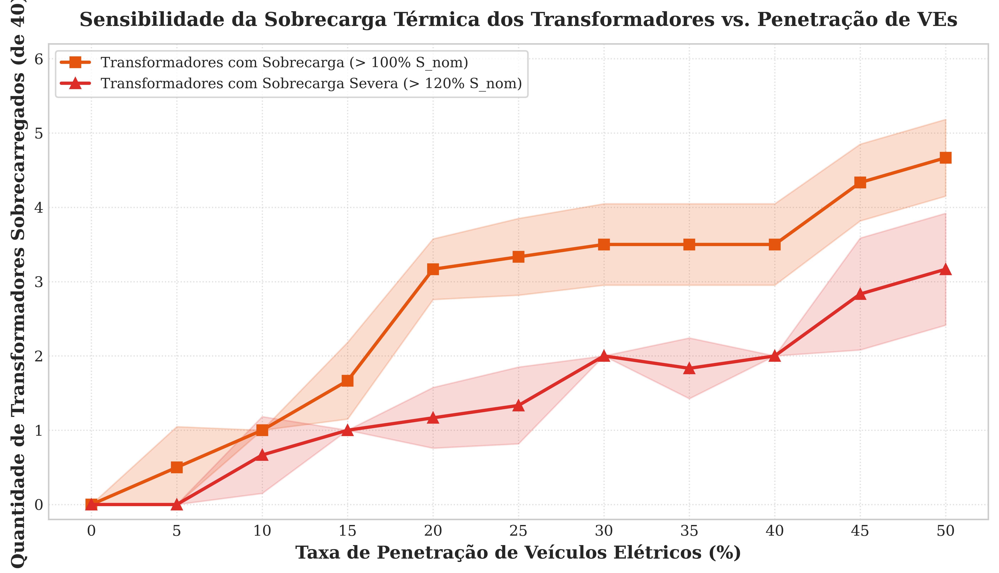

In [11]:
# FIGURA 9: Sensibilidade da Sobrecarga Térmica dos Transformadores
fig, ax = plt.subplots(figsize=(9.5, 5.5), dpi=600)
m_sob100 = df_resumo_trafos["n_sobrecarga_100_media"].values
s_sob100 = df_resumo_trafos["n_sobrecarga_100_std"].values
m_sob120 = df_resumo_trafos["n_sobrecarga_120_media"].values
s_sob120 = df_resumo_trafos["n_sobrecarga_120_std"].values

ax.plot(p_pct, m_sob100, marker="s", color="#e6550d", linewidth=2.2, markersize=7, label="Transformadores com Sobrecarga (> 100% S_nom)")
ax.fill_between(p_pct, np.maximum(0, m_sob100 - s_sob100), m_sob100 + s_sob100, color="#e6550d", alpha=0.2)

ax.plot(p_pct, m_sob120, marker="^", color="#de2d26", linewidth=2.2, markersize=7, label="Transformadores com Sobrecarga Severa (> 120% S_nom)")
ax.fill_between(p_pct, np.maximum(0, m_sob120 - s_sob120), m_sob120 + s_sob120, color="#de2d26", alpha=0.18)

ax.set_xlabel("Taxa de Penetração de Veículos Elétricos (%)", fontweight="bold")
ax.set_ylabel("Quantidade de Transformadores Sobrecarregados (de 40)", fontweight="bold")
ax.set_xticks(p_pct)
ax.set_ylim(-0.2, 6.2)
ax.set_yticks(range(0, 7))
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper left", frameon=True)
plt.title("Sensibilidade da Sobrecarga Térmica dos Transformadores vs. Penetração de VEs", fontweight="bold", pad=12)
plt.tight_layout()
salvar_figura(fig, "fig9_trafo_sobrecarga_vs_penetracao")
plt.show()

Salvo: fig10_trafo_envelhecimento_perda_vida_util_ieee.png e fig10_trafo_envelhecimento_perda_vida_util_ieee.pdf (600 DPI)


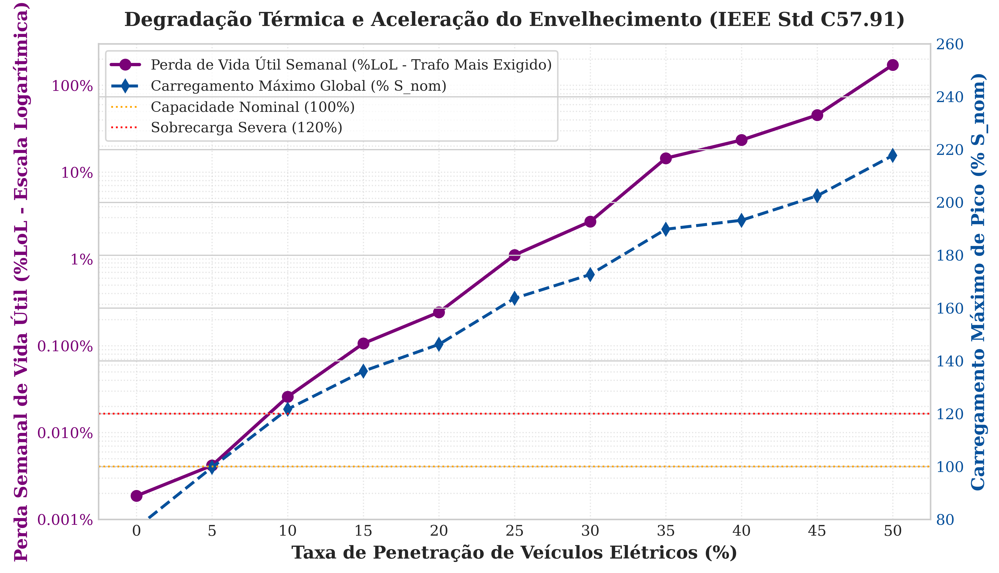

In [12]:
# FIGURA 10: Envelhecimento Térmico e Perda de Vida Útil (IEEE Std C57.91)
fig, ax1 = plt.subplots(figsize=(9.5, 5.5), dpi=600)
color1, color2 = "#7a0177", "#08519c"

ax1.set_xlabel("Taxa de Penetração de Veículos Elétricos (%)", fontweight="bold")
ax1.set_ylabel("Perda Semanal de Vida Útil (%LoL - Escala Logarítmica)", color=color1, fontweight="bold")
m_lol = df_resumo_trafos["lol_max_global_media"].values
m_lol_plot = np.maximum(m_lol, 1e-4)

line1 = ax1.plot(p_pct, m_lol_plot, marker="o", color=color1, linewidth=2.2, markersize=7, label="Perda de Vida Útil Semanal (%LoL - Trafo Mais Exigido)")
ax1.set_yscale("log")
ax1.set_ylim(1e-3, 300)
ax1.set_yticks([1e-3, 1e-2, 1e-1, 1, 10, 100])
ax1.get_yaxis().set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{y:g}%" if y >= 1 else f"{y:.3f}%".rstrip('0').rstrip('.')))
ax1.tick_params(axis="y", labelcolor=color1)

ax2 = ax1.twinx()
ax2.set_ylabel("Carregamento Máximo de Pico (% S_nom)", color=color2, fontweight="bold")
m_fcmax = df_resumo_trafos["fc_max_global_media"].values
line2 = ax2.plot(p_pct, m_fcmax, marker="d", color=color2, linewidth=2.0, linestyle="--", markersize=6, label="Carregamento Máximo Global (% S_nom)")
ax2.axhline(100.0, color="orange", linestyle=":", linewidth=1.2, label="Capacidade Nominal (100%)")
ax2.axhline(120.0, color="red", linestyle=":", linewidth=1.2, label="Sobrecarga Severa (120%)")
ax2.set_ylim(80, 260)
ax2.yaxis.set_major_locator(ticker.MultipleLocator(20))
ax2.tick_params(axis="y", labelcolor=color2)

ax1.set_xticks(p_pct)
ax1.grid(True, which="both", linestyle=":", alpha=0.5)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", frameon=True)
plt.title("Degradação Térmica e Aceleração do Envelhecimento (IEEE Std C57.91)", fontweight="bold", pad=12)
plt.tight_layout()
salvar_figura(fig, "fig10_trafo_envelhecimento_perda_vida_util_ieee")
plt.show()

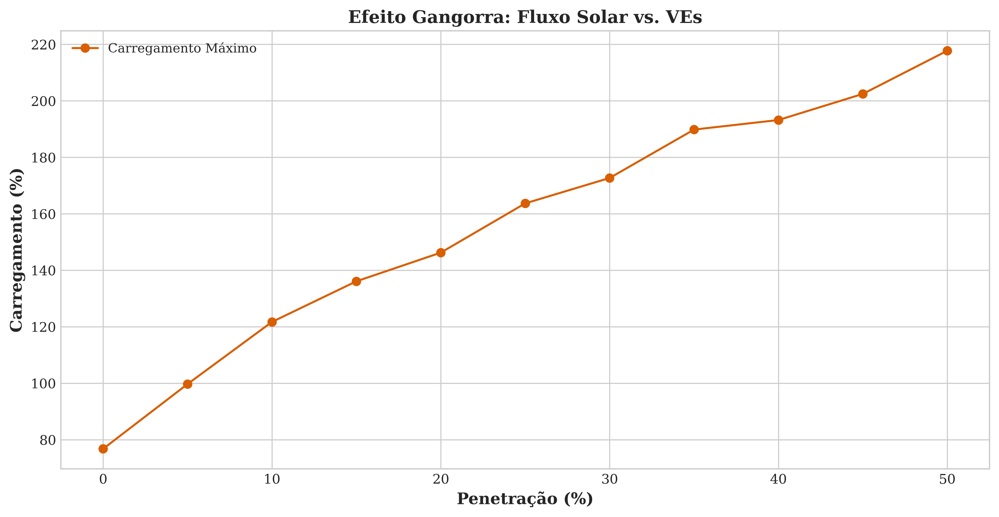

In [13]:
# FIGURA 11: Efeito Gangorra Semanal: Injeção Solar ao Meio-Dia vs. Pico de VEs à Noite
# Exibição do gráfico salvo em alta resolução
caminho_fig11 = FIGURAS_DIR / "fig11_trafo_efeito_gangorra_fluxo_reverso_vs_ve.png"
if caminho_fig11.exists():
    from IPython.display import Image, display
    display(Image(filename=str(caminho_fig11)))
else:
    print("Figura 11 ainda não gerada. Execute a célula final para renderizar.")

Salvo: fig12_hosting_capacity_confronto_tensao_vs_trafos.png e fig12_hosting_capacity_confronto_tensao_vs_trafos.pdf (600 DPI)


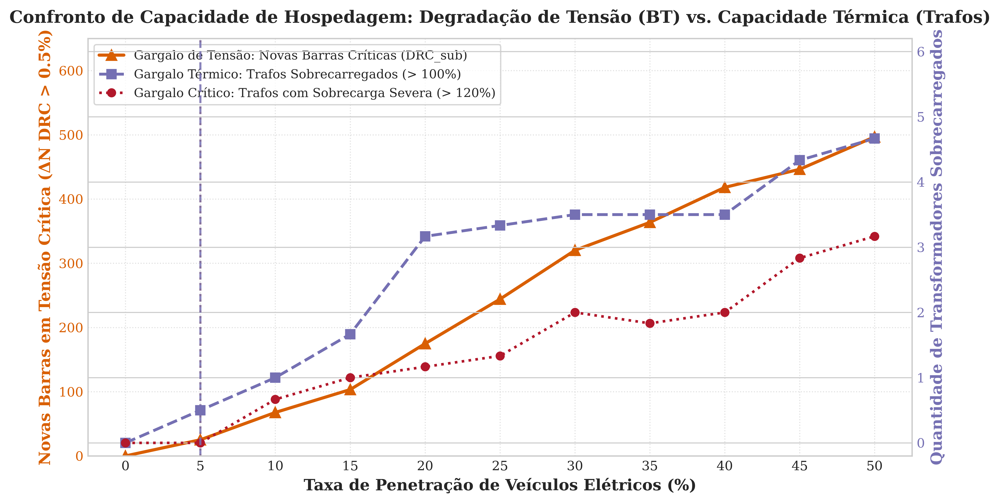

In [14]:
# FIGURA 12: Confronto de Hosting Capacity: Degradação de Tensão (BT) vs. Capacidade Térmica (Trafos)
fig, ax1 = plt.subplots(figsize=(10.0, 5.5), dpi=600)
cor_drc, cor_trf, cor_trf2 = "#d95f02", "#7570b3", "#b2182b"

ax1.set_xlabel("Taxa de Penetração de Veículos Elétricos (%)", fontweight="bold")
ax1.set_ylabel("Novas Barras em Tensão Crítica (ΔN DRC > 0.5%)", color=cor_drc, fontweight="bold")
d_drc = df_agregado["delta_n_barras_drc_sub_media"].values
line1 = ax1.plot(p_pct, d_drc, marker="^", color=cor_drc, linewidth=2.4, markersize=8, label="Gargalo de Tensão: Novas Barras Críticas (DRC_sub)")
ax1.set_ylim(0, 650)
ax1.yaxis.set_major_locator(ticker.MultipleLocator(100))
ax1.tick_params(axis="y", labelcolor=cor_drc)

ax2 = ax1.twinx()
ax2.set_ylabel("Quantidade de Transformadores Sobrecarregados", color=cor_trf, fontweight="bold")
line2 = ax2.plot(p_pct, df_resumo_trafos["n_sobrecarga_100_media"], marker="s", color=cor_trf, linewidth=2.2, linestyle="--", markersize=7, label="Gargalo Térmico: Trafos Sobrecarregados (> 100%)")
line3 = ax2.plot(p_pct, df_resumo_trafos["n_sobrecarga_120_media"], marker="o", color=cor_trf2, linewidth=2.0, linestyle=":", markersize=6, label="Gargalo Crítico: Trafos com Sobrecarga Severa (> 120%)")
ax2.set_ylim(-0.2, 6.2)
ax2.set_yticks(range(0, 7))
ax2.tick_params(axis="y", labelcolor=cor_trf)

ax1.set_xticks(p_pct)
ax1.grid(True, linestyle=":", alpha=0.6)

idx_hc_tensao = df_agregado[d_drc > 0].index
if len(idx_hc_tensao) > 0:
    p_hc_v = df_agregado.loc[idx_hc_tensao[0], "penetracao_pct"]
    ax1.axvline(p_hc_v, color=cor_drc, linestyle=":", linewidth=1.6, alpha=0.85, label=f"Limiar Tensão BT ({p_hc_v}%)")

idx_hc_trafo = df_resumo_trafos[df_resumo_trafos["n_sobrecarga_100_media"] > 0].index
if len(idx_hc_trafo) > 0:
    p_hc_trf = df_resumo_trafos.loc[idx_hc_trafo[0], "penetracao_pct"]
    ax2.axvline(p_hc_trf, color=cor_trf, linestyle="--", linewidth=1.6, alpha=0.85, label=f"Limiar Térmico Trafos ({p_hc_trf}%)")

lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left", frameon=True)
plt.title("Confronto de Capacidade de Hospedagem: Degradação de Tensão (BT) vs. Capacidade Térmica (Trafos)", fontweight="bold", pad=12)
plt.tight_layout()
salvar_figura(fig, "fig12_hosting_capacity_confronto_tensao_vs_trafos")
plt.show()

Salvo: fig13_trafo_distribuicao_carregamento_boxplot.png e fig13_trafo_distribuicao_carregamento_boxplot.pdf (600 DPI)


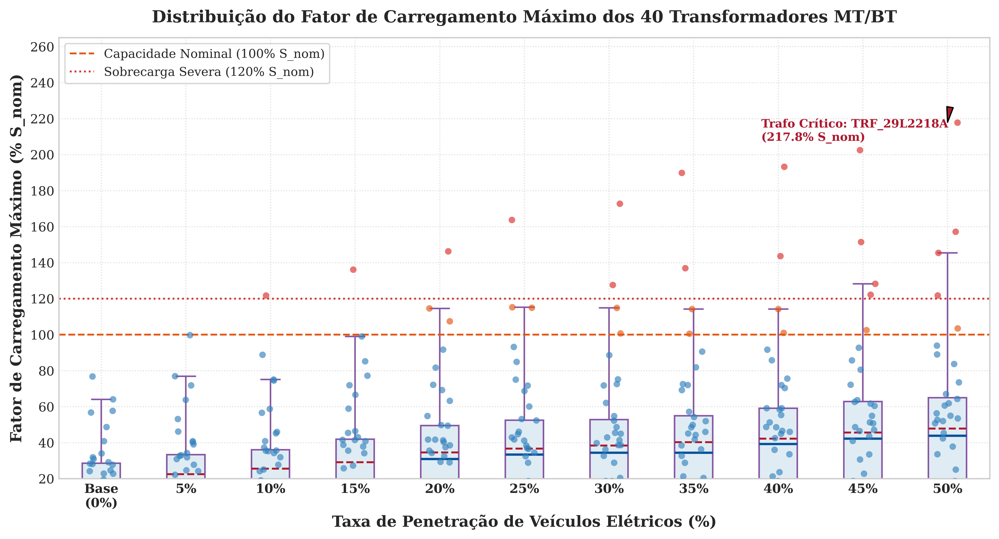

In [15]:
# FIGURA 13: Boxplot da Distribuição de Carregamento dos 40 Transformadores
fig, ax_box = plt.subplots(figsize=(11.0, 6.0), dpi=600)
cenarios_box = sorted(df_detalhado["penetracao_pct"].unique())
df_p_trafo = df_detalhado.groupby(["penetracao_pct", "trafo"])["fc_max_pct"].mean().reset_index()
dados_box = [df_p_trafo[df_p_trafo["penetracao_pct"] == p]["fc_max_pct"].values for p in cenarios_box]

ax_box.boxplot(
    dados_box, positions=range(len(cenarios_box)), widths=0.45, patch_artist=True,
    showmeans=True, meanline=True,
    meanprops=dict(color="#b2182b", linestyle="--", linewidth=1.5),
    medianprops=dict(color="#08519c", linewidth=1.8),
    boxprops=dict(facecolor="#e0ecf4", edgecolor="#8856a7", linewidth=1.2),
    whiskerprops=dict(color="#8856a7", linewidth=1.2),
    capprops=dict(color="#8856a7", linewidth=1.2),
    flierprops=dict(marker="", linestyle="none"),
)

np.random.seed(42)
for i, (p, vals) in enumerate(zip(cenarios_box, dados_box)):
    jitter = np.random.uniform(-0.15, 0.15, size=len(vals))
    cores_pts = ["#de2d26" if v > 120 else ("#e6550d" if v > 100 else "#3182bd") for v in vals]
    ax_box.scatter(np.full_like(vals, i) + jitter, vals, c=cores_pts, s=26, alpha=0.65, edgecolors="none", zorder=3)

ax_box.axhline(100.0, color="#e6550d", linestyle="--", linewidth=1.4, label="Capacidade Nominal (100% S_nom)")
ax_box.axhline(120.0, color="#de2d26", linestyle=":", linewidth=1.4, label="Sobrecarga Severa (120% S_nom)")
val_max_50 = max(dados_box[-1])
ax_box.annotate(
    f"Trafo Crítico: {trafo_mais_critico}\n({val_max_50:.1f}% S_nom)",
    xy=(len(cenarios_box) - 1, val_max_50),
    xytext=(len(cenarios_box) - 3.2, val_max_50 - 10),
    arrowprops=dict(facecolor="#b2182b", shrink=0.08, width=1, headwidth=5),
    fontsize=9.0, fontweight="bold", color="#b2182b",
)

ax_box.set_xticks(range(len(cenarios_box)))
ax_box.set_xticklabels([f"{int(p)}%" if p > 0 else "Base\n(0%)" for p in cenarios_box], fontweight="bold")
ax_box.set_xlabel("Taxa de Penetração de Veículos Elétricos (%)", fontweight="bold")
ax_box.set_ylabel("Fator de Carregamento Máximo (% S_nom)", fontweight="bold")
ax_box.set_ylim(20, 265)
ax_box.yaxis.set_major_locator(ticker.MultipleLocator(20))
ax_box.grid(True, linestyle=":", alpha=0.6)
ax_box.legend(loc="upper left", frameon=True, fontsize=9.5)
plt.title("Distribuição do Fator de Carregamento Máximo dos 40 Transformadores MT/BT", fontweight="bold", pad=12)
plt.tight_layout()
salvar_figura(fig, "fig13_trafo_distribuicao_carregamento_boxplot")
plt.show()

Salvo: fig14_trafo_carregamento_barras_empilhadas.png e fig14_trafo_carregamento_barras_empilhadas.pdf (600 DPI)


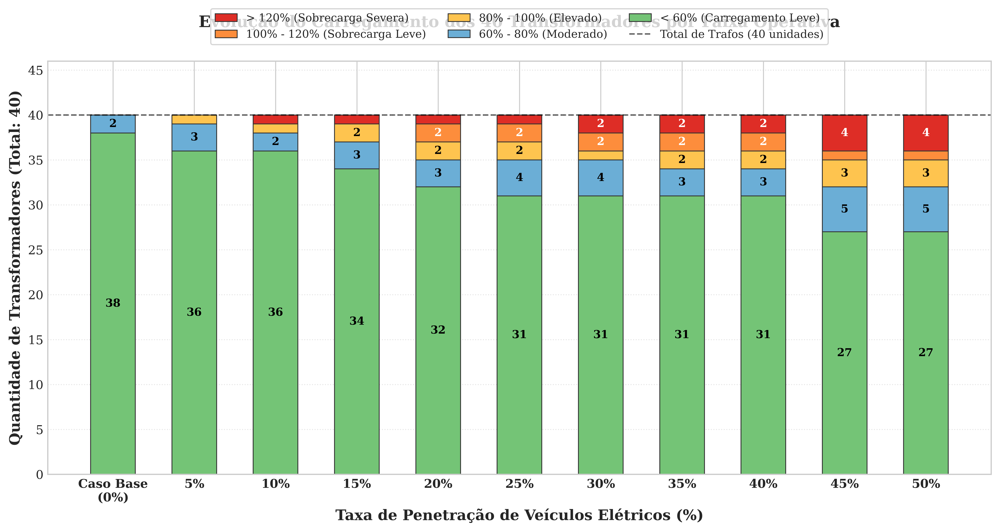

In [16]:
# FIGURA 14: Gráfico de Barras Empilhadas por Condição de Carregamento Máximo
fig, ax_stack = plt.subplots(figsize=(11.5, 6.2), dpi=600)
cenarios_stack = sorted(df_detalhado["penetracao_pct"].unique())
df_p_trafo = df_detalhado.groupby(["penetracao_pct", "trafo"])["fc_max_pct"].mean().reset_index()

categorias = [
    {"label": "< 60% (Carregamento Leve)", "cor": "#74c476", "filtro": lambda v: v < 60.0},
    {"label": "60% - 80% (Moderado)", "cor": "#6baed6", "filtro": lambda v: (v >= 60.0) & (v < 80.0)},
    {"label": "80% - 100% (Elevado)", "cor": "#fec44f", "filtro": lambda v: (v >= 80.0) & (v < 100.0)},
    {"label": "100% - 120% (Sobrecarga Leve)", "cor": "#fd8d3c", "filtro": lambda v: (v >= 100.0) & (v < 120.0)},
    {"label": "> 120% (Sobrecarga Severa)", "cor": "#de2d26", "filtro": lambda v: v >= 120.0},
]

x_pos = np.arange(len(cenarios_stack))
largura = 0.55
bottom_acum = np.zeros(len(cenarios_stack))

for cat in categorias:
    contagens = np.array([int(np.sum(cat["filtro"](df_p_trafo[df_p_trafo["penetracao_pct"] == p]["fc_max_pct"].values))) for p in cenarios_stack])
    barras = ax_stack.bar(x_pos, contagens, bottom=bottom_acum, width=largura, color=cat["cor"], label=cat["label"], edgecolor="#333333", linewidth=0.7)
    for i, (qtd, b_pos) in enumerate(zip(contagens, bottom_acum)):
        if qtd >= 2:
            ax_stack.text(
                x_pos[i], b_pos + qtd / 2.0, str(qtd), ha="center", va="center", fontsize=9.0, fontweight="bold",
                color="#000000" if cat["cor"] in ["#74c476", "#6baed6", "#fec44f"] else "#ffffff"
            )
    bottom_acum += contagens

ax_stack.axhline(40, color="black", linestyle="--", linewidth=1.2, alpha=0.6, label="Total de Trafos (40 unidades)")
ax_stack.set_xticks(x_pos)
ax_stack.set_xticklabels([f"{int(p)}%" if p > 0 else "Caso Base\n(0%)" for p in cenarios_stack], fontweight="bold")
ax_stack.set_xlabel("Taxa de Penetração de Veículos Elétricos (%)", fontweight="bold")
ax_stack.set_ylabel("Quantidade de Transformadores (Total: 40)", fontweight="bold")
ax_stack.set_ylim(0, 46)
ax_stack.yaxis.set_major_locator(ticker.MultipleLocator(5))
ax_stack.grid(True, linestyle=":", alpha=0.5, axis="y")

handles, labels = ax_stack.get_legend_handles_labels()
ax_stack.legend(handles[::-1], labels[::-1], loc="upper center", bbox_to_anchor=(0.5, 1.14), ncol=3, frameon=True, fontsize=9.0)
plt.title("Evolução do Carregamento dos 40 Transformadores por Faixa Operativa", fontweight="bold", pad=28)
plt.tight_layout()
salvar_figura(fig, "fig14_trafo_carregamento_barras_empilhadas")
plt.show()

## Módulo 4: Regeneração Geral e Exportação em Lote de Todas as Figuras
Executa a regeneração completa de todas as figuras chamando as funções do módulo `analisador_grade_tcc.py`.

In [17]:
from src.simulators.util.analisador_grade_tcc import (
    plotar_curvas_multissemente,
    plotar_figuras_transformadores,
)

print("Regenerando todas as 14 figuras a partir dos dados pré-processados...")
plotar_curvas_multissemente(
    df_agregado=df_agregado,
    df_todas=df_detalhado,
    figuras_dir=FIGURAS_DIR,
)

plotar_figuras_transformadores(
    df_resumo_trafos=df_resumo_trafos,
    df_ranking_trafos=df_ranking_trafos,
    df_detalhado=df_detalhado,
    figuras_dir=FIGURAS_DIR,
)
print("Todas as 14 figuras atualizadas em output/figuras/figuras_comparativas/ em 600 DPI e PDF vetorial!")

Regenerando todas as 14 figuras a partir dos dados pré-processados...
Salvo: fig1_impacto_relativo_pico_energia.png e fig1_impacto_relativo_pico_energia.pdf (600 DPI)
Salvo: fig2_hosting_capacity_novas_barras_prodist.png e fig2_hosting_capacity_novas_barras_prodist.pdf (600 DPI)
Salvo: fig3_vdi_subtensao_relativo.png e fig3_vdi_subtensao_relativo.pdf (600 DPI)
Salvo: fig4_tensao_minima_global_prodist.png e fig4_tensao_minima_global_prodist.pdf (600 DPI)
Salvo: fig5_tensao_media_global_todas_barras.png e fig5_tensao_media_global_todas_barras.pdf (600 DPI)
Salvo: fig6_perfil_semanal_barra_mais_afetada.png e fig6_perfil_semanal_barra_mais_afetada.pdf (600 DPI)
Salvo: fig7_sensibilidade_tensao_barra_mais_afetada.png e fig7_sensibilidade_tensao_barra_mais_afetada.pdf (600 DPI)
Salvo: fig8_trafo_curva_carga_24h_resfriamento_noturno.png e fig8_trafo_curva_carga_24h_resfriamento_noturno.pdf (600 DPI)
Salvo: fig9_trafo_sobrecarga_vs_penetracao.png e fig9_trafo_sobrecarga_vs_penetracao.pdf (600 